In [ ]:
import cdsapi

dataset = "reanalysis-era5-single-levels"
request = {
    "product_type": ["reanalysis"],
    "variable": ["snow_depth"],
    "year": [
        "1950", "1951", "1952",
        "1953", "1954", "1955",
        "1956", "1957", "1958",
        "1959", "1960", "1961",
        "1962", "1963", "1964",
        "1965", "1966", "1967",
        "1968", "1969", "1970",
        "1971", "1972", "1973",
        "1974", "1975", "1976",
        "1977", "1978", "1979",
        "1980", "1981", "1982",
        "1983", "1984", "1985",
        "1986", "1987"
    ],
    "month": [
        "01", "02", "10",
        "11", "12"
    ],
    "day": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12",
        "13", "14", "15",
        "16", "17", "18",
        "19", "20", "21",
        "22", "23", "24",
        "25", "26", "27",
        "28", "29", "30",
        "31"
    ],
    "time": [
        "00:00", "06:00", "12:00",
        "18:00"
    ],
    "grid": "1.0/1.0",
    "data_format": "grib",
    "download_format": "unarchived",
    "area": [90, 0, 20, 150]
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()

2026-07-13 17:52:16,717 INFO Request ID is 33e08228-1fc0-45a4-8978-8a5964ef4450
2026-07-13 17:52:16,795 INFO status has been updated to accepted


In [ ]:
import cdsapi

dataset = "reanalysis-era5-single-levels"
request = {
    "product_type": ["reanalysis"],
    "variable": ["snow_depth"],
    "year": [
        "1988", "1989", "1990",
        "1991", "1992", "1993",
        "1994", "1995", "1996",
        "1997", "1998", "1999",
        "2000", "2001", "2002",
        "2003", "2004", "2005",
        "2006", "2007", "2008",
        "2009", "2010", "2011",
        "2012", "2013", "2014",
        "2015", "2016", "2017",
        "2018", "2019", "2020",
        "2021", "2022", "2023",
        "2024", "2025"
    ],
    "month": [
        "01", "02", "10",
        "11", "12"
    ],
    "day": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12",
        "13", "14", "15",
        "16", "17", "18",
        "19", "20", "21",
        "22", "23", "24",
        "25", "26", "27",
        "28", "29", "30",
        "31"
    ],
    "time": [
        "00:00", "06:00", "12:00",
        "18:00"
    ],
    "grid": "1.0/1.0",
    "data_format": "grib",
    "download_format": "unarchived",
    "area": [90, 0, 20, 150]
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()

2026-07-13 17:52:59,622 INFO Request ID is d72b063e-3508-4548-b8a7-9d42fed33611
2026-07-13 17:52:59,706 INFO status has been updated to accepted


In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datetime import datetime, date

In [2]:
ds = xr.load_dataset("eurasian_snow_50_87.grib", engine="cfgrib")
var_daily1 = ds.sd.groupby(ds.sd.time.dt.date).mean()

In [3]:
ds = xr.load_dataset("eurasian_snow_88_25.grib", engine="cfgrib")
var_daily2 = ds.sd.groupby(ds.sd.time.dt.date).mean()

In [4]:
var_daily = xr.concat([var_daily1, var_daily2], dim='date')
var_daily = var_daily.reset_coords(['number', 'step', 'surface'], drop=True)

In [5]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [6]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [7]:
var_daily = var_daily.sel(time=slice("1950-07", "2025-06"))
var_daily = var_daily.assign_coords({'month_day': 31*var_daily['time.month'] + var_daily['time.day']})

In [8]:
weights = np.cos(np.deg2rad(var_daily.latitude))
weights.name = "weights"

In [9]:
lon_min = 70
lon_max = 140
lat_max = 60
lat_min = 40

var_daily_regmean = var_daily.sel(longitude=slice(lon_min,lon_max), latitude=slice(lat_max,lat_min)).weighted(weights).mean(dim=['longitude', 'latitude'])

In [10]:
month = var_daily_regmean.time.dt.month
day = var_daily_regmean.time.dt.day
var_daily_regmean = var_daily_regmean.sel(time=~((month == 2) & (day == 29)))
var_seasonmean_regmean = var_daily_regmean.coarsen(time=151).construct(time=("year", "date")).mean(dim='date')

(0.0, 0.05129813821736821)

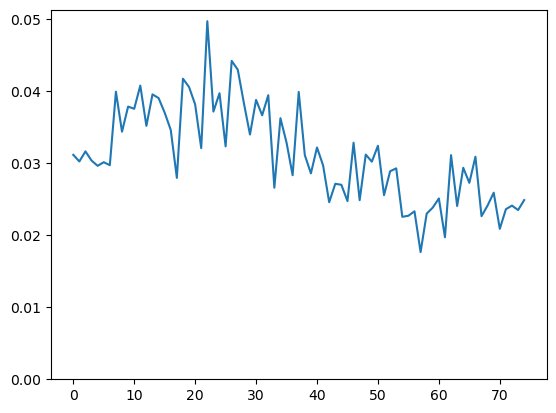

In [11]:
plt.plot(var_seasonmean_regmean.year, var_seasonmean_regmean)
plt.ylim(bottom=0)

In [12]:
var_7dMean_regmean = var_daily_regmean.rolling(time=7, min_periods=7, center=True).mean() 
month = var_7dMean_regmean.time.dt.month
day = var_7dMean_regmean.time.dt.day
var_7dMean_regmean = var_7dMean_regmean.sel(time=~( ((month==10)&(day<4)) | ((month==2)&(day>25)) ))

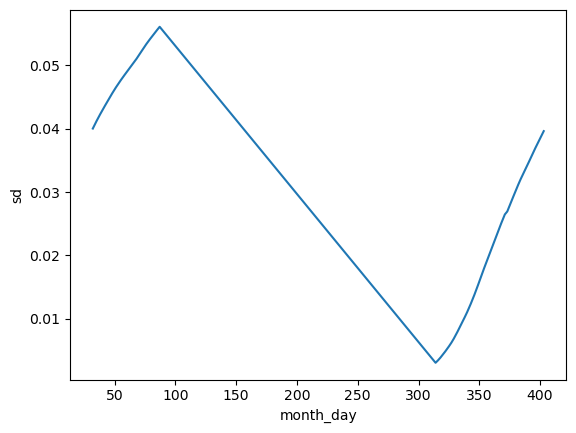

In [13]:
var_7dMean_regmean.groupby('month_day').mean().plot()

In [14]:
def lin_fit(da):
    return da.polyfit('time', 1).polyfit_coefficients

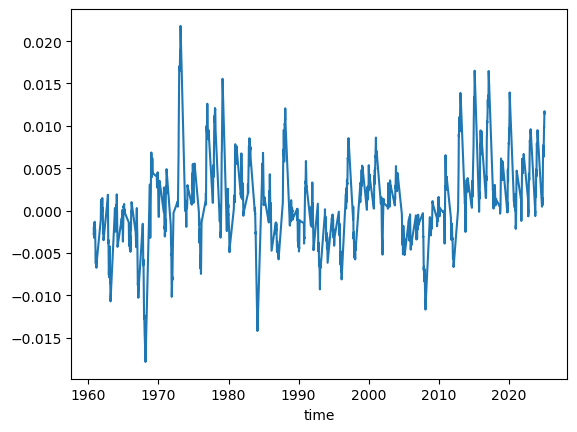

In [15]:
var_7dMean_regmean_train = var_7dMean_regmean.sel(time=slice("1960-07", "2010-06"))
fit_params = var_7dMean_regmean_train.groupby('month_day').apply(lin_fit)

def detrend(da):
    return da - xr.polyval(da.time, fit_params.sel(month_day=da.month_day[0]))
    
var_7dMean_regmean_anom = var_7dMean_regmean.groupby('month_day').apply(detrend)
var_7dMean_regmean_anom[:145*10] = np.nan
var_7dMean_regmean_anom.plot()

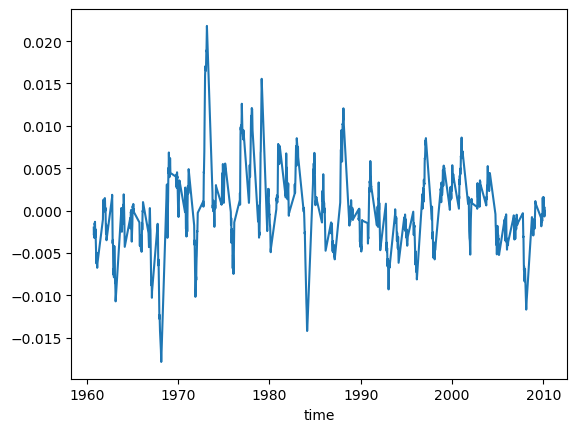

In [16]:
var_7dMean_regmean_anom.sel(time=slice("1960-07", "2010-06")).plot()

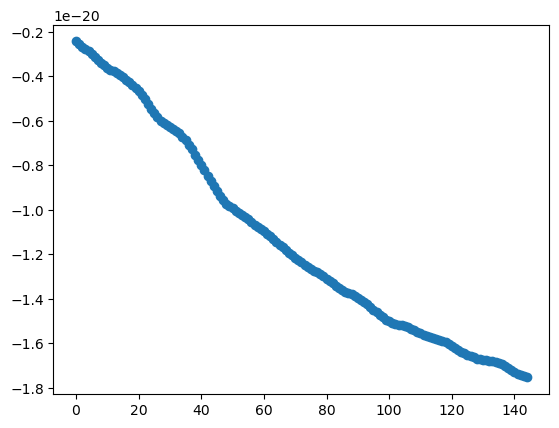

In [17]:
plt.plot(range(145), np.concatenate([fit_params[56:,0], fit_params[:56,0]]), 'o-')

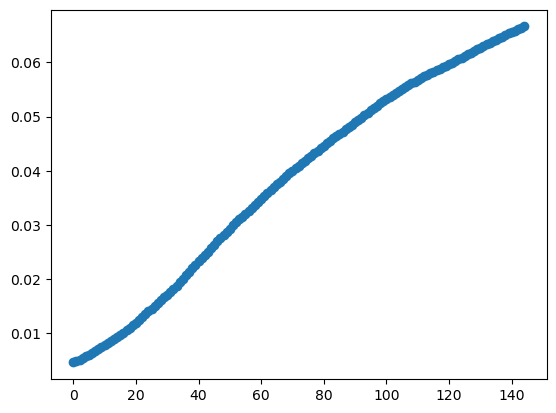

In [18]:
plt.plot(range(145), np.concatenate([fit_params[56:,1], fit_params[:56,1]]), 'o-')

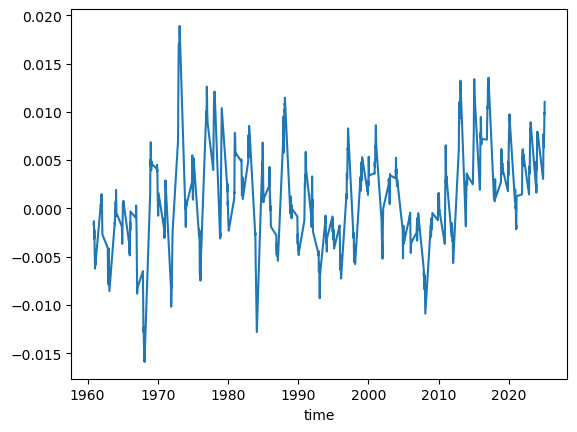

In [19]:
month = var_7dMean_regmean_anom.time.dt.month
day = var_7dMean_regmean_anom.time.dt.day
var_7dMean_regmean_anom_week3 = var_7dMean_regmean_anom.sel(time = ((month == 11) & (day >= 13)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 4)))
var_7dMean_regmean_anom_week4 = var_7dMean_regmean_anom.sel(time = ((month == 11) & (day >= 6)) | (month == 12) | ((month == 1) & (day <= 28)))
var_7dMean_regmean_anom_week5 = var_7dMean_regmean_anom.sel(time = ((month == 10) & (day >= 30)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 21)))
var_7dMean_regmean_anom_week3.plot()

In [20]:
df_var_week3 = var_7dMean_regmean_anom_week3.to_dataframe(name='snow_depth')
df_var_week3 = df_var_week3.drop(['month_day'], axis=1)
df_var_week3

,snow_depth
time,
1950-11-13,NaN
1950-11-14,NaN
1950-11-15,NaN
1950-11-16,NaN
1950-11-17,NaN
...,...
2025-01-31,0.010493
2025-02-01,0.010687
2025-02-02,0.010851


In [21]:
df_var_week4 = var_7dMean_regmean_anom_week4.to_dataframe(name='snow_depth')
df_var_week4 = df_var_week4.drop(['month_day'], axis=1)
df_var_week4

,snow_depth
time,
1950-11-06,NaN
1950-11-07,NaN
1950-11-08,NaN
1950-11-09,NaN
1950-11-10,NaN
...,...
2025-01-24,0.009890
2025-01-25,0.009884
2025-01-26,0.009812


In [22]:
df_var_week5 = var_7dMean_regmean_anom_week5.to_dataframe(name='snow_depth')
df_var_week5 = df_var_week5.drop(['month_day'], axis=1)
df_var_week5

,snow_depth
time,
1950-10-30,NaN
1950-10-31,NaN
1950-11-01,NaN
1950-11-02,NaN
1950-11-03,NaN
...,...
2025-01-17,0.008863
2025-01-18,0.008968
2025-01-19,0.009192


In [32]:
df_var_week3.to_csv('Siberian_snow_week3.csv')

In [23]:
df_var_week4.to_csv('Siberian_snow_week4.csv')
df_var_week5.to_csv('Siberian_snow_week5.csv')